## **Data Preparation and Modeling**

### **Import Modules**

In [1]:
import numpy as np
import joblib
import sklearn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sb
from scipy import stats
plt.style.use('ggplot')
import warnings
warnings.filterwarnings('ignore')

### **Load Cleaned Data**

In [2]:
df_cleaned = pd.read_csv('heart_disease_data_cleaned.csv')
# pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
df_cleaned.shape

(41638, 9)

In [3]:
df_cleaned.shape

(41638, 9)

In [4]:
for attribute in df_cleaned.columns:
    if  df_cleaned[attribute].dtype == object:
        df_cleaned[attribute] =  df_cleaned[attribute].astype('category')
        
        
df_cleaned['Year'] =  df_cleaned['Year'].astype('category') 
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41638 entries, 0 to 41637
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Year                 41638 non-null  category
 1   LocationDesc         41638 non-null  category
 2   Topic                41638 non-null  category
 3   Data_Value_Unit      41638 non-null  category
 4   Data_Value_Alt       41638 non-null  float64 
 5   LowConfidenceLimit   41638 non-null  float64 
 6   HighConfidenceLimit  41638 non-null  float64 
 7   Break_Out_Category   41638 non-null  category
 8   Break_Out            41638 non-null  category
dtypes: category(6), float64(3)
memory usage: 1.2 MB


### **Data Preparation**

#### **Onehot encoding for categorical attributes**

In [5]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import MinMaxScaler

# Apply ordinal encoding to the 'Year' column
ord_enc = OrdinalEncoder()
df_cleaned['Year'] = ord_enc.fit_transform(df_cleaned[['Year']])
# List of categorical attributes excluding 'Topic'
cat_attributes = list(df_cleaned.select_dtypes(include = ['category']).columns)
cat_attributes.remove('Topic')
# Apply one-hot encoding to the specified categorical columns (excluding 'Year')
df2 = pd.get_dummies(df_cleaned, columns = cat_attributes)
# Identify boolean columns
bool_columns = df2.select_dtypes(include='bool').columns
#  Convert boolean columns to integers (0 and 1)
df2[bool_columns] = df2[bool_columns].astype('uint8')
new_attr_list = list(df2.columns)
new_attr_list.remove('Topic')
df2 = df2[new_attr_list]
df2.head()

,Year,Data_Value_Alt,LowConfidenceLimit,HighConfidenceLimit,LocationDesc_Alabama,LocationDesc_Alaska,LocationDesc_Arizona,LocationDesc_Arkansas,LocationDesc_California,LocationDesc_Colorado,LocationDesc_Connecticut,LocationDesc_Delaware,LocationDesc_Florida,LocationDesc_Georgia,LocationDesc_Hawaii,LocationDesc_Idaho,LocationDesc_Illinois,LocationDesc_Indiana,LocationDesc_Iowa,LocationDesc_Kansas,LocationDesc_Kentucky,LocationDesc_Louisiana,LocationDesc_Maine,LocationDesc_Maryland,LocationDesc_Massachusetts,LocationDesc_Michigan,LocationDesc_Minnesota,LocationDesc_Mississippi,LocationDesc_Missouri,LocationDesc_Montana,LocationDesc_Nebraska,LocationDesc_Nevada,LocationDesc_New Hampshire,LocationDesc_New Jersey,LocationDesc_New Mexico,LocationDesc_New York,LocationDesc_North Carolina,LocationDesc_North Dakota,LocationDesc_Ohio,LocationDesc_Oklahoma,LocationDesc_Oregon,LocationDesc_Pennsylvania,LocationDesc_Rhode Island,LocationDesc_South Carolina,LocationDesc_South Dakota,LocationDesc_Tennessee,LocationDesc_Texas,LocationDesc_United States,LocationDesc_Utah,LocationDesc_Vermont,LocationDesc_Virginia,LocationDesc_Washington,"LocationDesc_Washington, DC",LocationDesc_West Virginia,LocationDesc_Wisconsin,LocationDesc_Wyoming,Data_Value_Unit_Percent (%),"Data_Value_Unit_Rate per 1,000",Break_Out_Category_Age,Break_Out_Category_Gender,Break_Out_Category_Overall,Break_Out_Category_Race,Break_Out_65+,Break_Out_75+,Break_Out_Female,Break_Out_Hispanic,Break_Out_Male,Break_Out_Non-Hispanic Black,Break_Out_Non-Hispanic White,Break_Out_Other,Break_Out_Overall
0,2.0,5.2,5.1,5.3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0
1,1.0,5.1,5.1,5.2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0
2,3.0,8.5,8.4,8.5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0
3,4.0,5.1,5.1,5.1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0
4,0.0,6.1,6.1,6.1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1


In [6]:
df2.shape

(41638, 71)

In [7]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41638 entries, 0 to 41637
Data columns (total 71 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            41638 non-null  float64
 1   Data_Value_Alt                  41638 non-null  float64
 2   LowConfidenceLimit              41638 non-null  float64
 3   HighConfidenceLimit             41638 non-null  float64
 4   LocationDesc_Alabama            41638 non-null  uint8  
 5   LocationDesc_Alaska             41638 non-null  uint8  
 6   LocationDesc_Arizona            41638 non-null  uint8  
 7   LocationDesc_Arkansas           41638 non-null  uint8  
 8   LocationDesc_California         41638 non-null  uint8  
 9   LocationDesc_Colorado           41638 non-null  uint8  
 10  LocationDesc_Connecticut        41638 non-null  uint8  
 11  LocationDesc_Delaware           41638 non-null  uint8  
 12  LocationDesc_Florida            

#### **Normalization for numerical attributes**
- We normalize the numerical attributes to bring them to a similar scale, ensuring that the algorithm can learn effectively without being biased towards features with larger magnitudes. Since we have identified outliers and the features in our dataset have skewed distributions, we opted to use the RobustScaler method.

In [8]:
#Normalization
# List of numerical attributes (excluding the binary columns resulting from one-hot encoding)
from sklearn.preprocessing import RobustScaler
numerical_attributes = list(df2.select_dtypes(include=['int64', 'float64']).columns)
numerical_attributes.remove('Year')  # Exclude 'Year' if it's included in numerical attributes

# Apply Min-Max scaling to the numerical columns only
#scaler = MinMaxScaler()
# Fit and transform using RobustScaler
scaler = RobustScaler()
df2[numerical_attributes] = scaler.fit_transform(df2[numerical_attributes])

# Display the resulting DataFrame
print(df2.head())


   Year  Data_Value_Alt  LowConfidenceLimit  HighConfidenceLimit  \
0   2.0       -0.337209           -0.207547            -0.415301   
1   1.0       -0.343023           -0.207547            -0.420765   
2   3.0       -0.145349            0.000000            -0.240437   
3   4.0       -0.343023           -0.207547            -0.426230   
4   0.0       -0.284884           -0.144654            -0.371585   

   LocationDesc_Alabama  LocationDesc_Alaska  LocationDesc_Arizona  \
0                     0                    0                     0   
1                     0                    0                     0   
2                     0                    0                     0   
3                     0                    0                     0   
4                     0                    0                     0   

   LocationDesc_Arkansas  LocationDesc_California  LocationDesc_Colorado  \
0                      0                        0                      0   
1                 

In [9]:
# Define the replacement dictionary
replacement_dict = {
    'Heart Failure': 0,
    'Coronary Heart Disease': 1,
    'Stroke': 2,
    'Major Cardiovascular Disease': 3,
    'Diseases of the Heart (Heart Disease)': 4,
    'Acute Myocardial Infarction (Heart Attack)': 5
}

# Replace values in the 'Topic' column with numerical values
df_cleaned['Topic'].replace(replacement_dict, inplace=True)

### **Modeling**

#### **Split dataset**
- As the first step, we divided the dataset into two subsets:
Training Temporary Set (train_tmp): This subset comprised 80% of the data, serving as the primary training data for model development.
Test Set: The remaining 20% of the data formed the test set, which was reserved for final model evaluation.

- Step 2: Further Splitting

Subsequently, we further partitioned the train_tmp set into two distinct subsets:
Training Set (train): Consisting of 80% of train_tmp, this subset was utilized for training our models.
Validation Set (val): Comprising the remaining 20% of train_tmp, this subset was dedicated to validating and fine-tuning the trained models.

In [10]:
from sklearn.model_selection import train_test_split
import numpy as np

In [11]:
x = np.array(df2.values)
y = np.array(df_cleaned['Topic'].values)

seed = 12062024
test_size = 0.2
val_size = 0.2

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=val_size, random_state=seed)

In [12]:
!pip install imbalanced-learn



 #### **Resampling for Minority Class Enrichment**

In [13]:
#from imblearn.combine import SMOTEENN
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE

# Apply BorderlineSMOTE
smote = BorderlineSMOTE(random_state=seed, sampling_strategy='minority')
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

#smote_enn = SMOTEENN(random_state=seed, sampling_strategy='auto')
#x_train_resampled, y_train_resampled = smote_enn.fit_resample(x_train, y_train)


#### **Create the models**
- In this step, we trained and evaluated multiple machine learning models using the resampled training data (x_train_smote, y_train_smote) and the validation set (x_val, y_val). A variety of classifiers, including decision trees
-  (C45 and CART)
-   random forests (RF)
-   neural networks (NeuralNetwork)
-    gradient boosting (GB)
-    AdaBoost (AB)
-  naive Bayes (NB)
- and k-nearest neighbors (KNN), were considered for evaluation.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, recall_score, precision_score, f1_score
from sklearn.metrics import classification_report
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier

In [15]:
models = []
models.append(('C45', DecisionTreeClassifier(criterion='entropy', random_state=seed)))
models.append(('CART', DecisionTreeClassifier(criterion='gini', random_state=seed)))
models.append(('RF', RandomForestClassifier(n_estimators=100, random_state=seed)))
models.append(('NeuralNetwork', MLPClassifier(hidden_layer_sizes=(50, 10, ), max_iter=500, verbose=True, 
                                              random_state=seed)))

models.append(('GB', GradientBoostingClassifier(random_state=seed)))
models.append(('AB', AdaBoostClassifier(random_state=seed)))
models.append(('NB', GaussianNB()))
models.append(('KNN', KNeighborsClassifier()))

# evaluate each model in turn

for name, model in models:
    print(name)
    
    model.fit(x_train_smote, y_train_smote)
    y_val_pred = model.predict(x_val)
    
    print('Classification metrics: ')
    print(classification_report(y_val, y_val_pred))

C45
Classification metrics: 
              precision    recall  f1-score   support

           0       0.92      0.91      0.92      3009
           1       0.68      0.75      0.71       705
           2       0.71      0.70      0.70       726
           3       0.95      0.94      0.94       762
           4       0.94      0.95      0.94       770
           5       0.85      0.84      0.85       690

    accuracy                           0.87      6662
   macro avg       0.84      0.85      0.85      6662
weighted avg       0.87      0.87      0.87      6662

CART
Classification metrics: 
              precision    recall  f1-score   support

           0       0.92      0.91      0.92      3009
           1       0.68      0.74      0.71       705
           2       0.69      0.68      0.69       726
           3       0.95      0.95      0.95       762
           4       0.95      0.94      0.94       770
           5       0.85      0.83      0.84       690

    accuracy      

#### **Evaluation Model**

#### **Cross-Validation Performance Comparison**
- In this step, we conducted 5-fold cross-validation for each machine learning model using the resampled training data (x_train_smote, y_train_smote). The mean accuracy scores of the models across all folds were computed and stored in a DataFrame (kfold_results).

In [ ]:
from sklearn.model_selection import KFold, cross_val_score


kfold_results = pd.DataFrame()

for name, model in models:
    kfold = KFold(n_splits=5, random_state=seed, shuffle=True)
    cv_results = cross_val_score(model, x_train_smote, y_train_smote, cv=kfold, scoring='accuracy')
    kfold_results[name] = cv_results

In [ ]:
kfold_results


##### **Finding best model**
We considered F1 score and accuracy as the most important classification metrics.
By comparing the F1 scores and accuracies of the different models, we identified the MLPClassifier as the model that performs best according to our chosen metrics.

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier


In [20]:
model = MLPClassifier( random_state=seed)
model.fit(x_train, y_train)
predictions = model.predict(x_test)
print(classification_report(y_test, predictions))


              precision    recall  f1-score   support

           0       0.94      0.93      0.93      3734
           1       0.79      0.79      0.79       952
           2       0.71      0.73      0.72       844
           3       0.97      0.98      0.97       930
           4       0.98      0.96      0.97       912
           5       0.86      0.87      0.86       956

    accuracy                           0.90      8328
   macro avg       0.87      0.88      0.87      8328
weighted avg       0.90      0.90      0.90      8328



In [21]:
print(f'Accuracy: {accuracy_score(y_test, predictions):.2f}')

Accuracy: 0.90


#### **Confusion_Matrix**

In [22]:
def make_confusion_matrix(cf, categories='auto', cbar=True, cmap='Blues', title=None):
    group_counts = [f'{value}\n' for value in cf.flatten()]

    box_labels = [f'{v1}'.strip() for v1 in group_counts]
    box_labels = np.asarray(box_labels).reshape(cf.shape[0],cf.shape[1])

    sb.heatmap(cf, annot=box_labels, fmt='', cmap=cmap, cbar=cbar, xticklabels=categories, yticklabels=categories)

    
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    
    if title:
        plt.title(title)

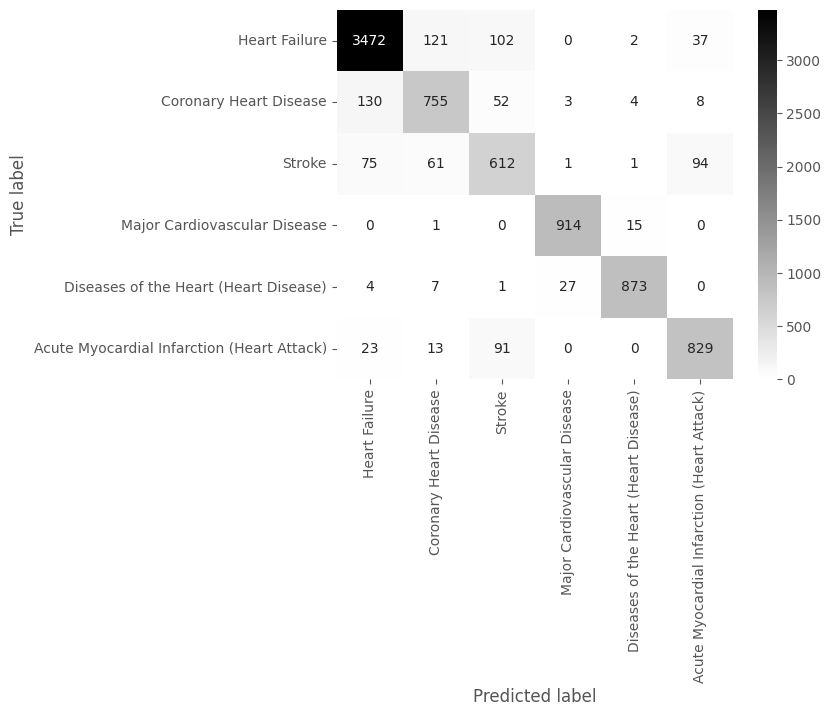

In [23]:
categories = ['Heart Failure', 'Coronary Heart Disease','Stroke','Major Cardiovascular Disease','Diseases of the Heart (Heart Disease)','Acute Myocardial Infarction (Heart Attack)']
make_confusion_matrix(confusion_matrix(y_test, predictions), categories=categories, cmap='binary')

##### **Compute the Roc Curve for each class**

In [ ]:
from sklearn.metrics import roc_curve, auc

In [26]:
one_hot_encoding = np.array(pd.get_dummies(y_test, columns = ['Topic']))
probs = []
model.fit(x_train, y_train)
probs.append(model.predict_proba(x_test))
print(model)

MLPClassifier(random_state=12062024)


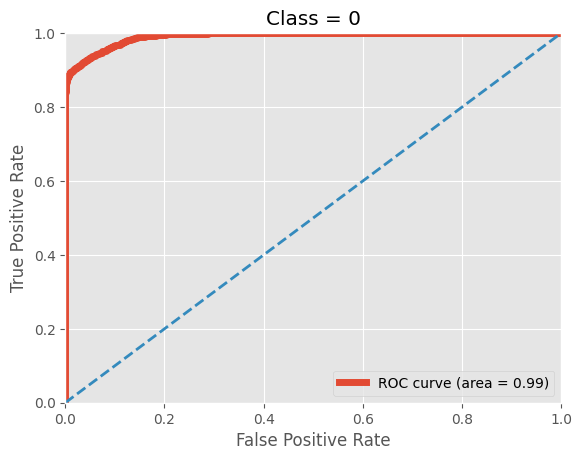

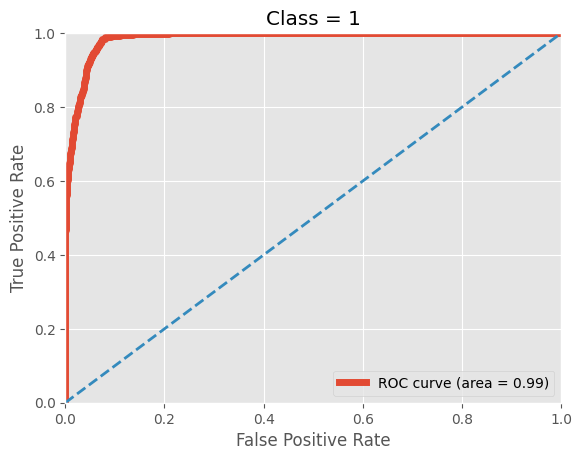

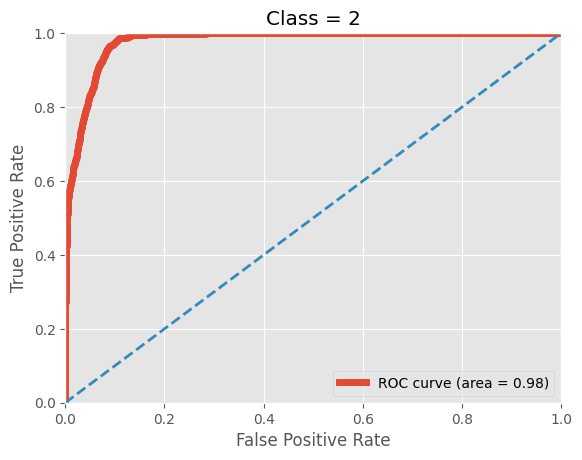

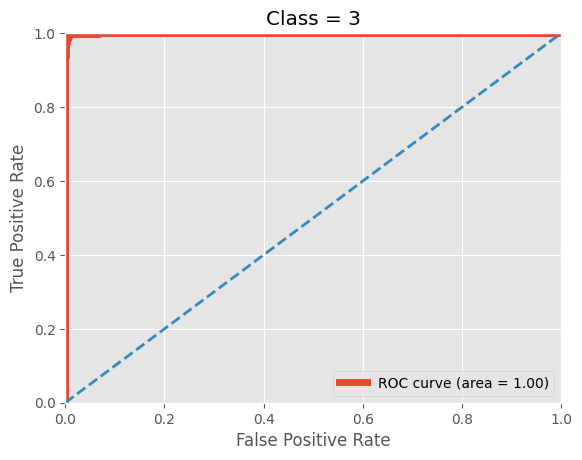

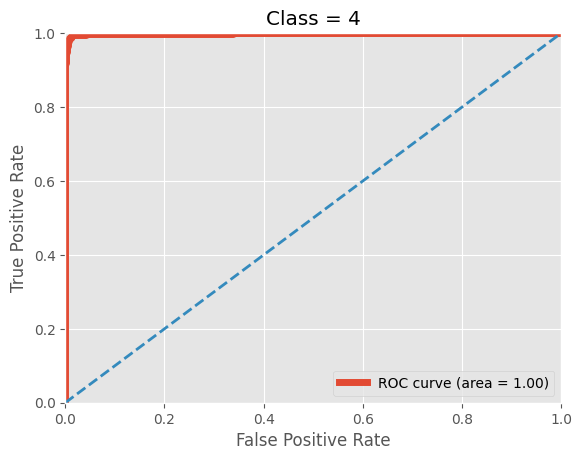

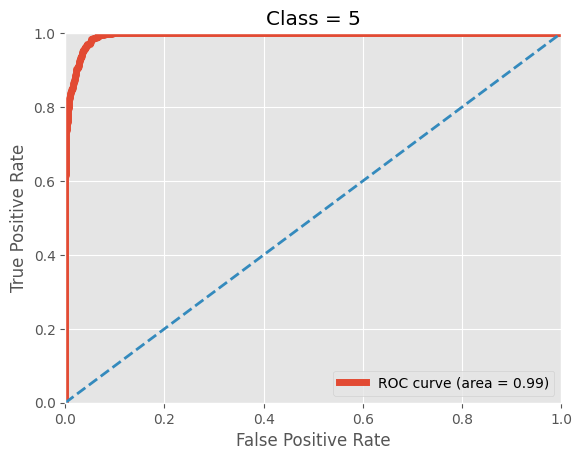

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np
import pandas as pd

# Assuming y_test, x_train, y_train, and x_test are already defined

# One-hot encode the test labels
one_hot_encoding = np.array(pd.get_dummies(y_test, columns=['Topic']))

# Train the model and get prediction probabilities
model.fit(x_train, y_train)
probs = model.predict_proba(x_test)

# Initialize dictionaries to hold the false positive rates, true positive rates, and AUC values
fpr = dict()
tpr = dict()
roc_auc = dict()

# Loop through each class
for i in range(len(np.unique(y_test))):
    plt.figure()
    
    # Compute ROC curve and ROC area for each class
    fpr[i], tpr[i], _ = roc_curve(one_hot_encoding[:, i], probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Plot ROC curve
    plt.plot(fpr[i], tpr[i], lw=5, label=f'ROC curve (area = {roc_auc[i]:.2f})')

    # Plot the diagonal line (random classifier)
    plt.plot([0, 1], [0, 1], lw=2, linestyle='--')
    
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Class = ' + str(np.unique(y_test)[i]))
    plt.legend(loc='lower right')
    
    plt.show()
